In [10]:
import pandas as pd
import matplotlib.pyplot as plt
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


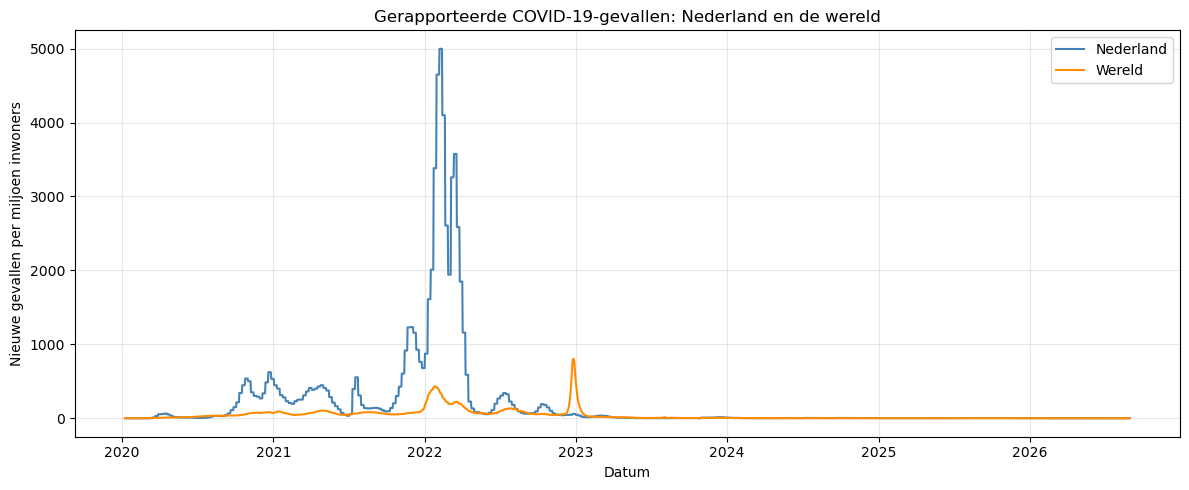

In [ ]:
covid = pd.read_csv("daily-new-confirmed-covid-19-cases-per-million-people.csv")
covid["Day"] = pd.to_datetime(covid["Day"])

covid_nl = covid.loc[
    covid["Entity"] == "Netherlands"
].sort_values("Day")

covid_world = covid.loc[
    covid["Entity"] == "World"
].sort_values("Day")

if covid_world.empty:
    raise ValueError("De categorie 'World' ontbreekt in dit CSV-bestand.")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    covid_nl["Day"],
    covid_nl["New cases (per 1M)"],
    label="Nederland",
    color="steelblue",
    linewidth=1.5
)

ax.plot(
    covid_world["Day"],
    covid_world["New cases (per 1M)"],
    label="Wereld",
    color="darkorange",
    linewidth=1.5
)
ax.set_title("Gerapporteerde COVID-19-gevallen: Nederland en de wereld")
ax.set_xlabel("Datum")
ax.set_ylabel("Nieuwe gevallen per miljoen inwoners")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()


In [13]:
schiphol = pd.read_excel("Monthly_traffic_data_1992-current-2.xlsx")

In [17]:
covid = pd.read_csv("daily-new-confirmed-covid-19-cases-per-million-people.csv")
covid["Day"] = pd.to_datetime(covid["Day"])
covid_nl = covid.loc[covid["Entity"] == "Netherlands"].copy().sort_values("Day")
covid_nl["Datum"] = (covid_nl["Day"].dt.to_period("M").dt.to_timestamp())
covid_maand = (covid_nl.groupby("Datum", as_index=False)["New cases (per 1M)"].mean().rename(columns={"New cases (per 1M)": "Covid_per_miljoen"}))

schiphol_raw = pd.read_excel(
    "Monthly_traffic_data_1992-current-2.xlsx",
    sheet_name="Standard&Poors",
    header=8
)

schiphol = schiphol_raw.iloc[:, [0, 1, 6, 7, 8, 10, 11]].copy()
schiphol.columns = [
    "Jaar",
    "Maand",
    "Europa",
    "Intercontinentaal",
    "Totaal",
    "OD",
    "Transfer"
]

schiphol["Jaar"] = pd.to_numeric(schiphol["Jaar"], errors="coerce").ffill()

maanden = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

schiphol = schiphol.loc[schiphol["Maand"].isin(maanden)].copy()
schiphol["Jaar"] = schiphol["Jaar"].astype(int)
schiphol["Maandnummer"] = schiphol["Maand"].map(maanden)

schiphol["Datum"] = pd.to_datetime({
    "year": schiphol["Jaar"],
    "month": schiphol["Maandnummer"],
    "day": 1
})

categorieen = ["Europa", "Intercontinentaal", "Totaal", "OD", "Transfer"]

for kolom in categorieen:
    schiphol[kolom] = pd.to_numeric(
        schiphol[kolom], errors="raise"
    )

schiphol = schiphol.sort_values("Datum")

if schiphol["Datum"].duplicated().any():
    raise ValueError("Er staan dubbele maanden in de Schiphol-data.")

referentie = schiphol.loc[
    schiphol["Jaar"] == 2019
].set_index("Maandnummer")

if len(referentie) != 12:
    raise ValueError("Voor 2019 zijn niet alle twaalf maanden beschikbaar.")

for kolom in categorieen:
    basis = schiphol["Maandnummer"].map(referentie[kolom])
    schiphol[f"{kolom}_index"] = schiphol[kolom] / basis * 100

pandemie = schiphol.loc[
    schiphol["Jaar"].between(2020, 2022)
].merge(
    covid_maand,
    on="Datum",
    how="left",
    validate="one_to_one"
)

print("De data zijn klaar voor de grafieken.")

De data zijn klaar voor de grafieken.


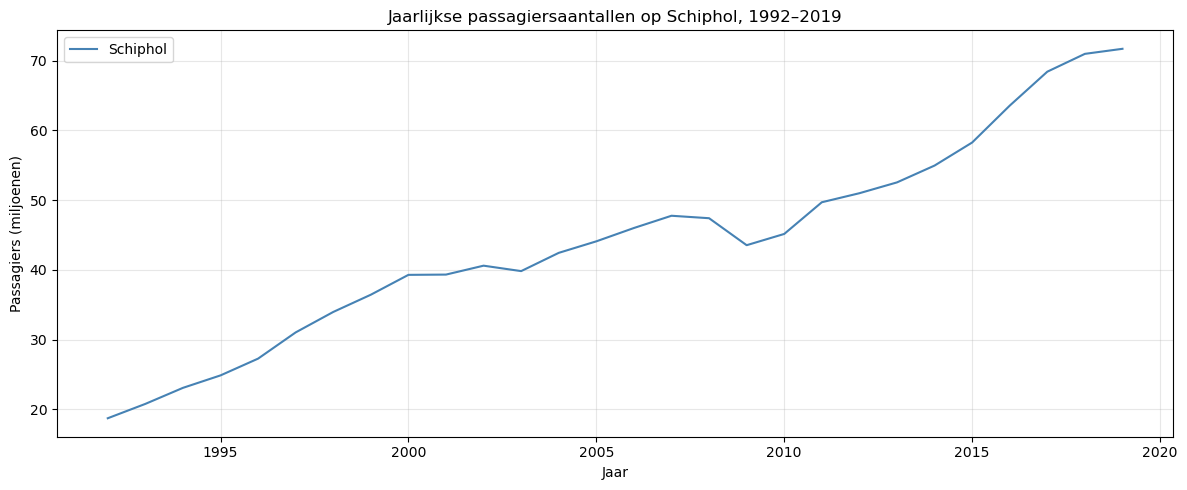

In [18]:
voor_covid = schiphol.loc[
    schiphol["Jaar"].between(1992, 2019)
]

jaar_totalen = (
    voor_covid.groupby("Jaar", as_index=False)["Totaal"].sum()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    jaar_totalen["Jaar"],
    jaar_totalen["Totaal"] / 1_000_000,
    label="Schiphol",
    color="steelblue",
    linewidth=1.5
)

ax.set_title("Jaarlijkse passagiersaantallen op Schiphol, 1992–2019")
ax.set_xlabel("Jaar")
ax.set_ylabel("Passagiers (miljoenen)")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

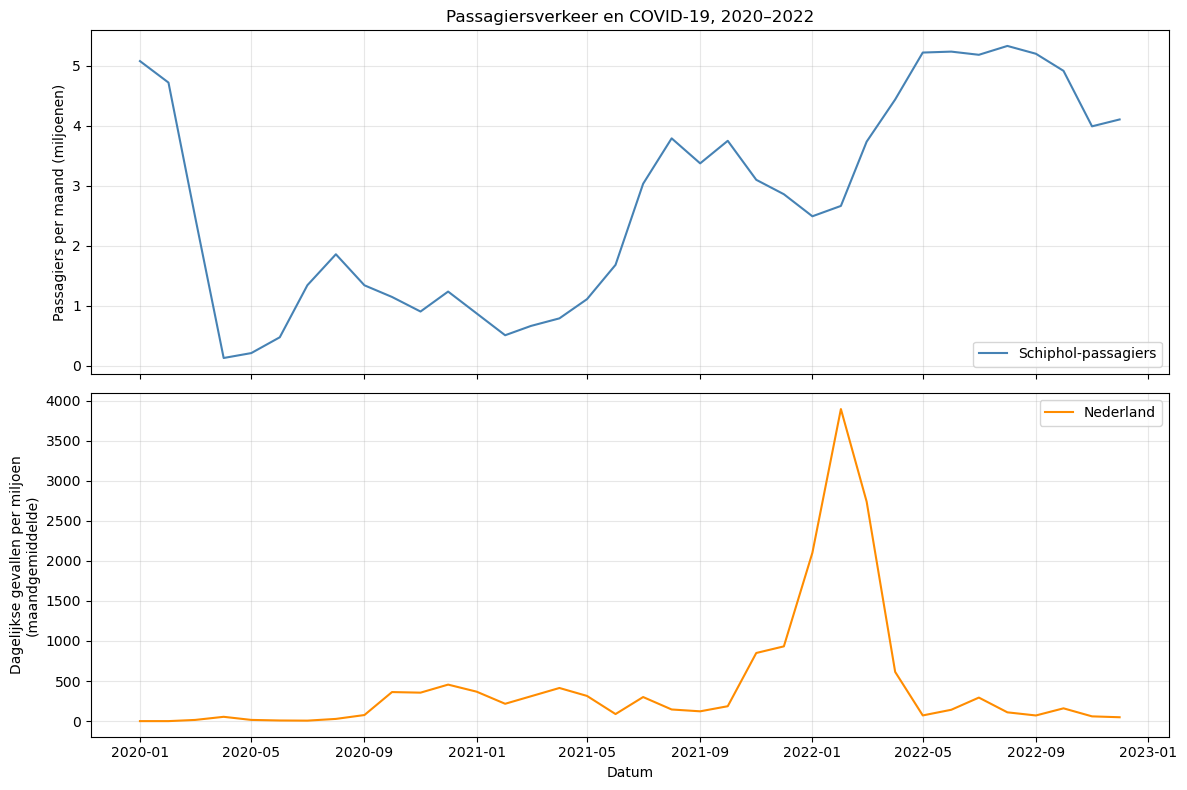

In [19]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

ax1.plot(
    pandemie["Datum"],
    pandemie["Totaal"] / 1_000_000,
    label="Schiphol-passagiers",
    color="steelblue",
    linewidth=1.5
)

ax1.set_title("Passagiersverkeer en COVID-19, 2020–2022")
ax1.set_ylabel("Passagiers per maand (miljoenen)")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(
    pandemie["Datum"],
    pandemie["Covid_per_miljoen"],
    label="Nederland",
    color="darkorange",
    linewidth=1.5
)

ax2.set_xlabel("Datum")
ax2.set_ylabel("Dagelijkse gevallen per miljoen\n(maandgemiddelde)")
ax2.legend()
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

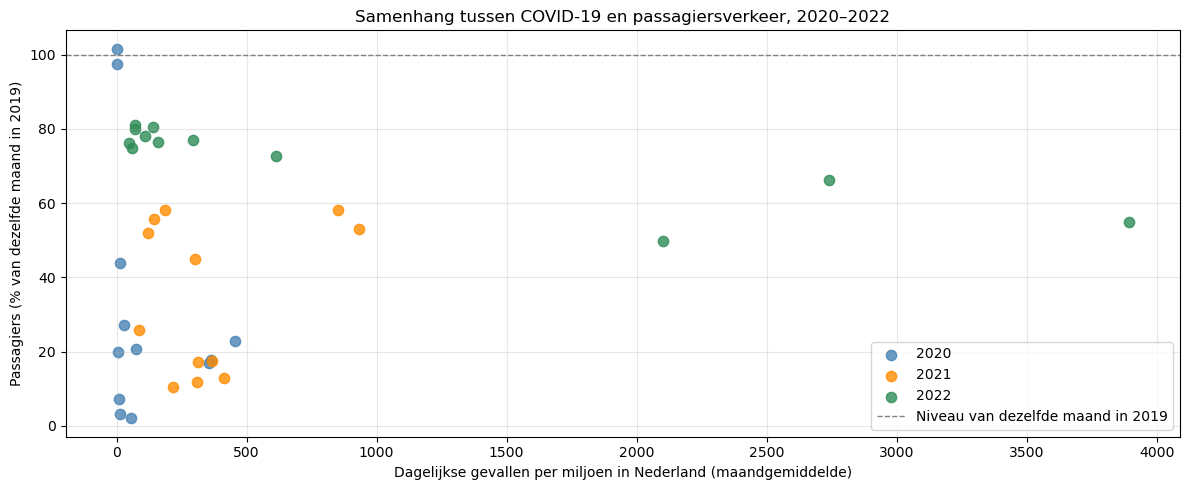

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))

for jaar, kleur in [
    (2020, "steelblue"),
    (2021, "darkorange"),
    (2022, "seagreen")
]:
    data = pandemie.loc[pandemie["Jaar"] == jaar]

    ax.scatter(
        data["Covid_per_miljoen"],
        data["Totaal_index"],
        label=str(jaar),
        color=kleur,
        s=55,
        alpha=0.8
    )

ax.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Niveau van dezelfde maand in 2019"
)

ax.set_title("Samenhang tussen COVID-19 en passagiersverkeer, 2020–2022")
ax.set_xlabel("Dagelijkse gevallen per miljoen in Nederland (maandgemiddelde)")
ax.set_ylabel("Passagiers (% van dezelfde maand in 2019)")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

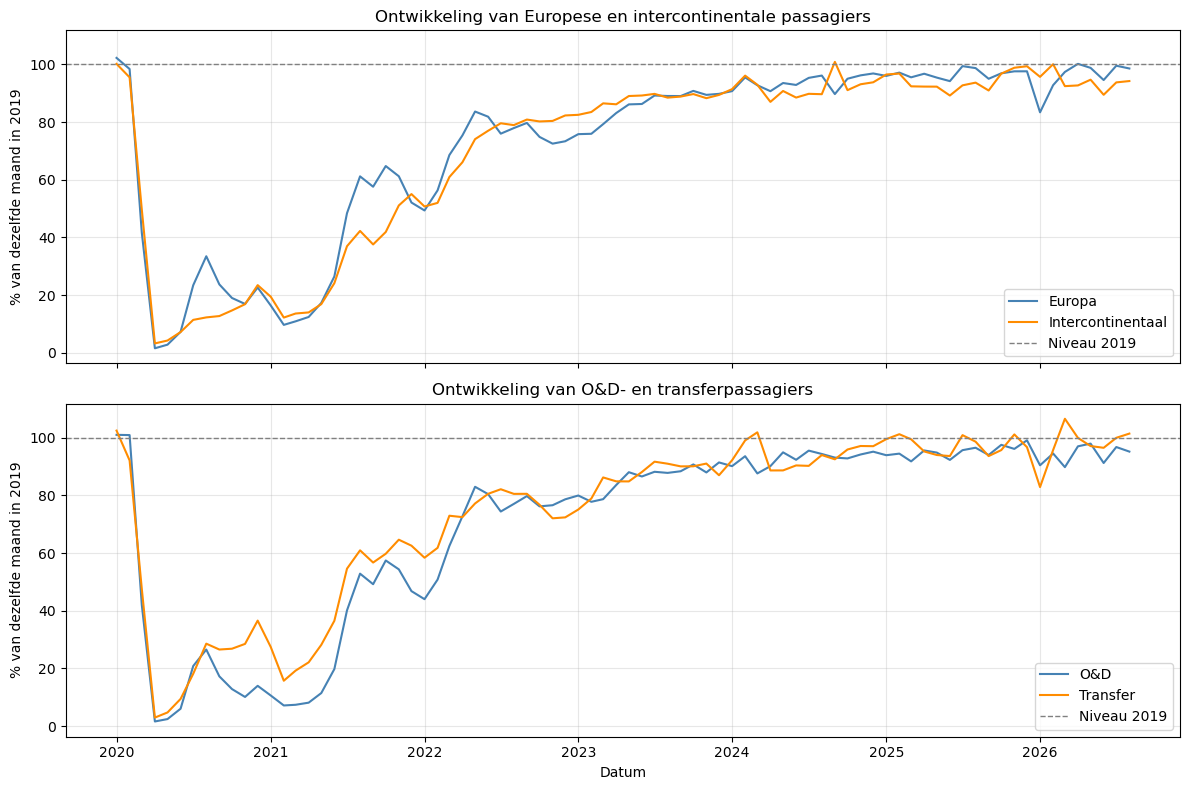

In [21]:
groepen = schiphol.loc[
    schiphol["Jaar"] >= 2020
].copy()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, sharey=True
)

ax1.plot(
    groepen["Datum"],
    groepen["Europa_index"],
    label="Europa",
    color="steelblue",
    linewidth=1.5
)

ax1.plot(
    groepen["Datum"],
    groepen["Intercontinentaal_index"],
    label="Intercontinentaal",
    color="darkorange",
    linewidth=1.5
)

ax1.set_title("Ontwikkeling van Europese en intercontinentale passagiers")
ax1.set_ylabel("% van dezelfde maand in 2019")

ax2.plot(
    groepen["Datum"],
    groepen["OD_index"],
    label="O&D",
    color="steelblue",
    linewidth=1.5
)

ax2.plot(
    groepen["Datum"],
    groepen["Transfer_index"],
    label="Transfer",
    color="darkorange",
    linewidth=1.5
)

ax2.set_title("Ontwikkeling van O&D- en transferpassagiers")
ax2.set_xlabel("Datum")
ax2.set_ylabel("% van dezelfde maand in 2019")

for ax in [ax1, ax2]:
    ax.axhline(
        100,
        color="gray",
        linestyle="--",
        linewidth=1,
        label="Niveau 2019"
    )
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

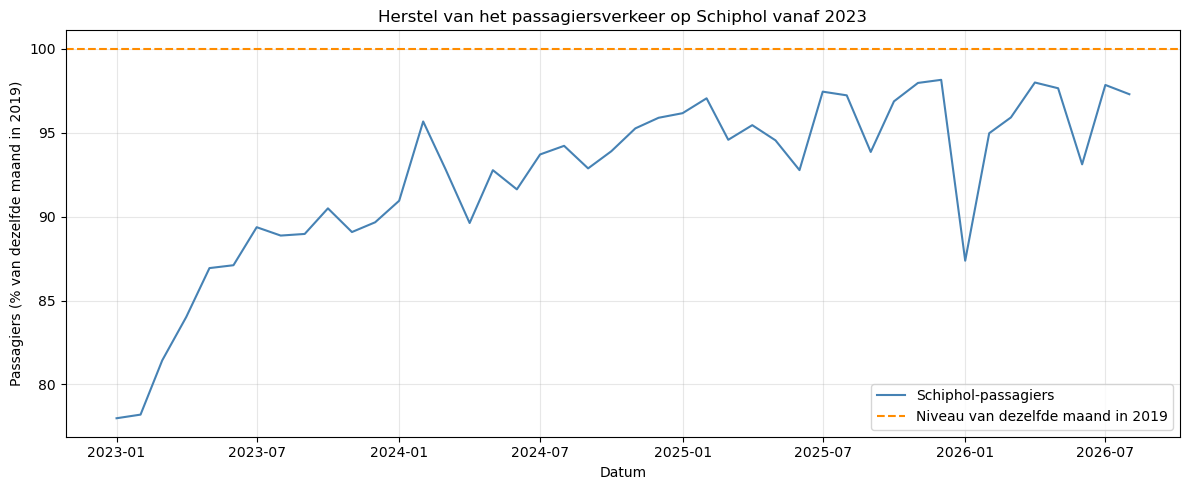

In [22]:
herstel = schiphol.loc[
    schiphol["Jaar"] >= 2023
].copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    herstel["Datum"],
    herstel["Totaal_index"],
    label="Schiphol-passagiers",
    color="steelblue",
    linewidth=1.5
)

ax.axhline(
    100,
    color="darkorange",
    linestyle="--",
    linewidth=1.5,
    label="Niveau van dezelfde maand in 2019"
)

ax.set_title("Herstel van het passagiersverkeer op Schiphol vanaf 2023")
ax.set_xlabel("Datum")
ax.set_ylabel("Passagiers (% van dezelfde maand in 2019)")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()